# Exercise 6

In [ ]:
import matplotlib.pyplot as plt 
import numpy as np

In [4]:
import numpy as np
from urllib.request import urlopen
url = "http://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
raw_data = urlopen(url)
dataset = np.loadtxt(raw_data, delimiter=",")
print(dataset.shape)

(1372, 5)


In [6]:
X=dataset[:,[1,3]]
Y=dataset[:,4]
print(X.shape)
print(Y.shape)

(1372, 2)
(1372,)


## 6.1

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

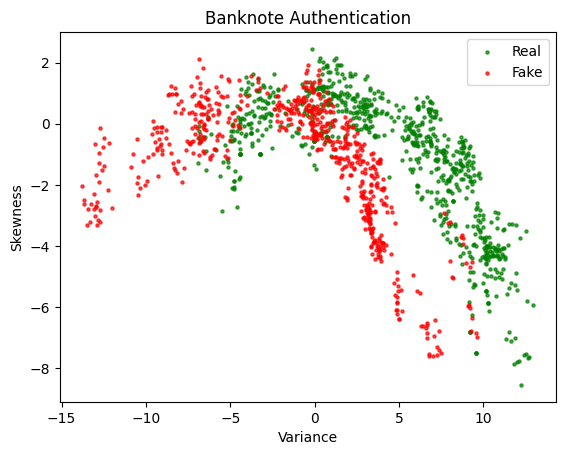

In [17]:
real = X[Y==0, :]
fake = X[Y==1, :]
plt.scatter(real[:, 0], real[:, 1], color="green", alpha=0.7, label="Real", s=5)
plt.scatter(fake[:, 0], fake[:, 1], color="red", alpha=0.7, label="Fake", s=5)
plt.title("Banknote Authentication")
plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.legend()
plt.show()

No the real and fake data points cannot be separated with a straight line.

## 6.2

In [29]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD

model = Sequential([
    Dense(1, input_shape=(X.shape[1],), activation="sigmoid")
])

model.compile(optimizer=SGD(learning_rate=0.15),
              loss="binary_crossentropy",
              metrics=["accuracy"])

history = model.fit(X, Y,
                    epochs=400,
                    batch_size=128)

Epoch 1/400
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 165ms/step - accuracy: 0.4375 - loss: 1.2613

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5831 - loss: 0.8159  
Epoch 2/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6633 - loss: 0.5673 
Epoch 3/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7223 - loss: 0.5252 
Epoch 4/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7332 - loss: 0.5183 
Epoch 5/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7347 - loss: 0.5178 
Epoch 6/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7289 - loss: 0.5164 
Epoch 7/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7230 - loss: 0.5133 
Epoch 8/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7172 - loss: 0.5130 
Epoch 9/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7208 - loss: 0.5129 
Epoch 10/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7114 - loss: 0.5130 
Epoch 11/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7194 - loss: 0.5129 
Epoch 12/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy:

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

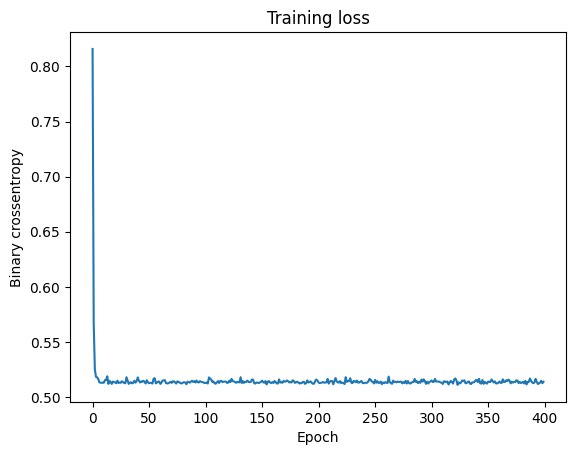

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

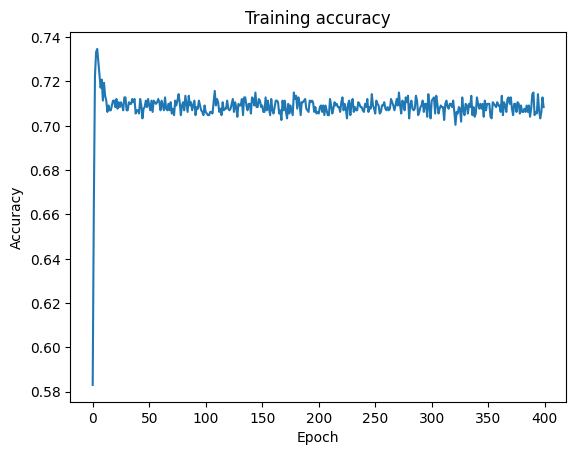

In [30]:
# Visualisation
plt.plot(history.history["loss"])
plt.title("Training loss")
plt.xlabel("Epoch")
plt.ylabel("Binary crossentropy")
plt.show()

plt.plot(history.history["accuracy"])
plt.title("Training accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

The logistic regression model reached 
an accuracy of 0.70 on the training set, which is relatively poor for a binary 
classification task a random classifier would already achieve 0.50. 
The data is not linearly separable in the original feature space.

## 6.3

In [31]:
x1list = np.linspace(np.min(X[:,0])-2, np.max(X[:,0])+2, 50)
x2list = np.linspace(np.min(X[:,1])-2, np.max(X[:,1])+2, 50)

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 443us/step


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

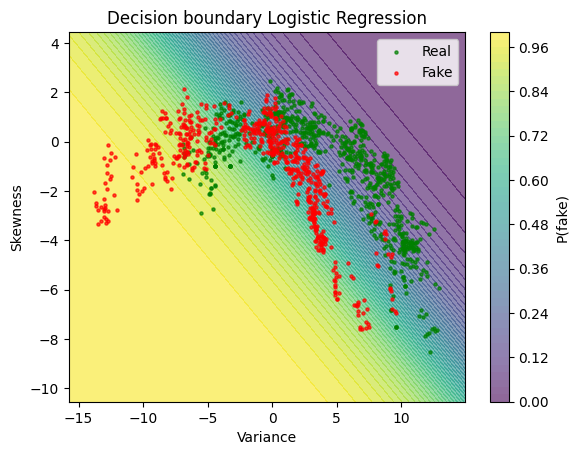

In [36]:

x1grid, x2grid = np.meshgrid(x1list, x2list)

grid_points = np.c_[x1grid.ravel(), x2grid.ravel()]
Z = model.predict(grid_points)                         
Z = Z.reshape(x1grid.shape)                        

plt.contourf(x1grid, x2grid, Z, levels=50, cmap="viridis", alpha=0.6)
plt.colorbar(label="P(fake)")

plt.scatter(real[:, 0], real[:, 1], color="green", s=5, alpha=0.7, label="Real")
plt.scatter(fake[:, 0], fake[:, 1], color="red",   s=5, alpha=0.7, label="Fake")

plt.title("Decision boundary Logistic Regression")
plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.legend()
plt.show()

## 6.4

In [38]:
model = Sequential([
    Dense(1, input_shape=(X.shape[1],), activation="sigmoid"),
    Dense(8, input_shape=(X.shape[1],), activation="sigmoid"),
    Dense(2, input_shape=(X.shape[1],), activation="softmax")
])

model.compile(optimizer=SGD(learning_rate=0.15),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

from tensorflow.keras.utils import to_categorical

Y_c= to_categorical(Y,2)

history = model.fit(X, Y_c,
                    epochs=400,
                    batch_size=128)

Epoch 1/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5160 - loss: 0.6954  
Epoch 2/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5554 - loss: 0.6875 
Epoch 3/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5554 - loss: 0.6861 
Epoch 4/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5554 - loss: 0.6848 
Epoch 5/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5554 - loss: 0.6851 
Epoch 6/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5554 - loss: 0.6831 
Epoch 7/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5554 - loss: 0.6802 
Epoch 8/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5554 - loss: 0.6779 
Epoch 9/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5554 - loss: 0.6750 
Epoch 10/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5554 - loss: 0.6699 
Epoch 11/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5554 - loss: 0.6646 
Epoch 12/400
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

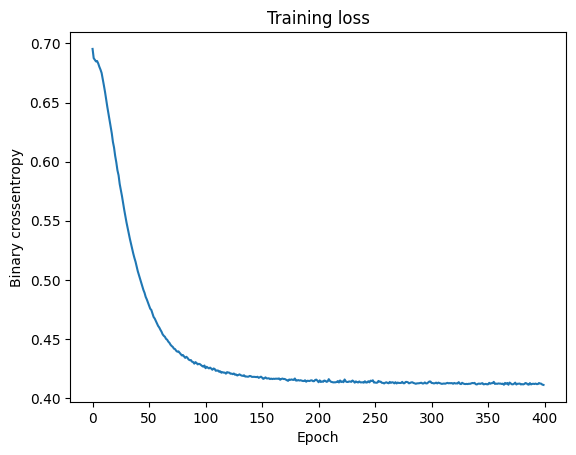

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

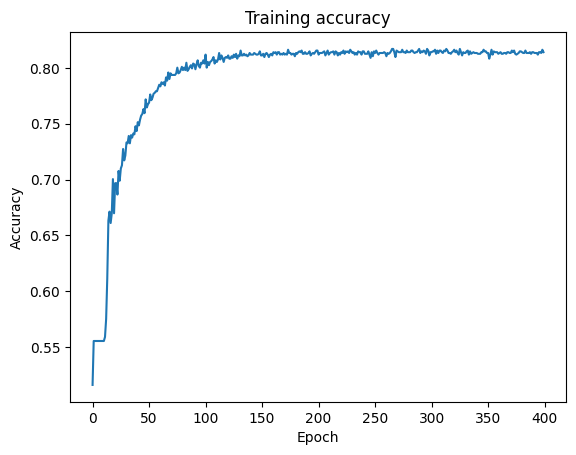

In [39]:
# Visualisation
plt.plot(history.history["loss"])
plt.title("Training loss")
plt.xlabel("Epoch")
plt.ylabel("Binary crossentropy")
plt.show()

plt.plot(history.history["accuracy"])
plt.title("Training accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

We achieved better result, this time the accuracy reached 0.81.

## 6.5

In [45]:
model.predict(np.reshape(np.array([0.0,0.1]),(1,2)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


array([[0.29521906, 0.7047809 ]], dtype=float32)

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 438us/step


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

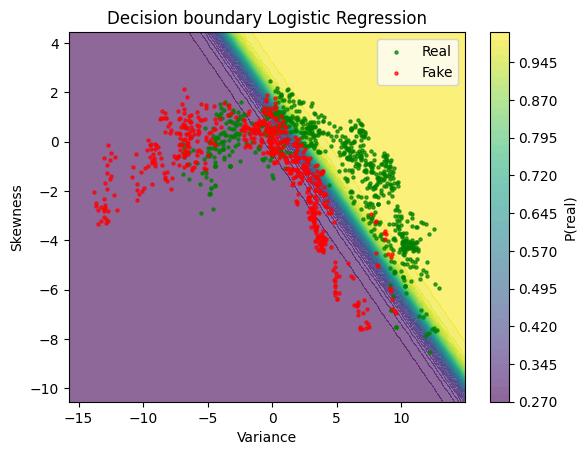

In [50]:
x1grid, x2grid = np.meshgrid(x1list, x2list)

grid_points = np.c_[x1grid.ravel(), x2grid.ravel()]
Z = model.predict(grid_points)[:, 0]           
Z = Z.reshape(x1grid.shape)

plt.contourf(x1grid, x2grid, Z, levels=50, cmap="viridis", alpha=0.6)
plt.colorbar(label="P(real)")

plt.scatter(real[:, 0], real[:, 1], color="green", s=5, alpha=0.7, label="Real")
plt.scatter(fake[:, 0], fake[:, 1], color="red",   s=5, alpha=0.7, label="Fake")

plt.title("Decision boundary Logistic Regression")
plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.legend()
plt.show()

## Comparison: Single Neuron vs Multi-Layer Model

The single neuron model achieved ~70% accuracy, limited by its linear decision 
boundary. The multi-layer model improves significantly by learning a non-linear 
boundary, visible in the contour plot, with higher confidence predictions for 
both classes.

Some misclassifications remain  mostly real banknotes predicted as fake 
(false negatives).